# 01 · Análisis exploratorio de datos (EDA)
**TráficoIA · Proyecto Final, versión 3 · Semana 1 (lunes 16 de noviembre)**

Equipo N.º ____ · Integrantes: ______________________

Este cuaderno explora (1) el dataset tabular *Metro Interstate Traffic Volume* y (2) el dataset de imágenes *GTSRB*, y termina definiendo la variable objetivo y las métricas de cada módulo.

> **Antes de ejecutar:** `python src/descargar_datos.py` desde la raíz del repositorio, con el entorno `proyecto_ia` activado.

In [1]:
import sys, warnings
from pathlib import Path

# Permite importar src/ aunque el cuaderno se ejecute desde notebooks/
RAIZ = Path.cwd().resolve()
if RAIZ.name == "notebooks":
    RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

from src import config, datos

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 30)
config.FIGURAS.mkdir(parents=True, exist_ok=True)

def guardar(nombre):
    plt.tight_layout()
    plt.savefig(config.FIGURAS / f"{nombre}.png", dpi=130)

print("Raíz del proyecto:", RAIZ)

Raíz del proyecto: C:\Users\pajar\OneDrive\Documentos\Uni\IAVOID\Proyecto\proyecto_ia_semana1\proyecto_ia


## Parte A · Dataset tabular: Metro Interstate Traffic Volume

### A.1 Carga y estructura

In [2]:
crudo = datos.cargar_trafico_crudo()
print(f"{crudo.shape[0]:,} filas x {crudo.shape[1]} columnas")
crudo.head()

48,204 filas x 9 columnas


,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,date_time,traffic_volume
0,NaN,288.28,0.0,0.0,40,Clouds,scattered clouds,2012-10-02 09:00:00,5545
1,NaN,289.36,0.0,0.0,75,Clouds,broken clouds,2012-10-02 10:00:00,4516
2,NaN,289.58,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 11:00:00,4767
3,NaN,290.13,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 12:00:00,5026
4,NaN,291.14,0.0,0.0,75,Clouds,broken clouds,2012-10-02 13:00:00,4918


In [3]:
crudo.info()

<class 'pandas.DataFrame'>
RangeIndex: 48204 entries, 0 to 48203
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   holiday              61 non-null     str    
 1   temp                 48204 non-null  float64
 2   rain_1h              48204 non-null  float64
 3   snow_1h              48204 non-null  float64
 4   clouds_all           48204 non-null  int64  
 5   weather_main         48204 non-null  str    
 6   weather_description  48204 non-null  str    
 7   date_time            48204 non-null  str    
 8   traffic_volume       48204 non-null  int64  
dtypes: float64(3), int64(2), str(4)
memory usage: 5.0 MB


**Diccionario de variables** (fuente: UCI): `holiday` (festivo o `None`), `temp` (Kelvin), `rain_1h` y `snow_1h` (mm en la hora), `clouds_all` (% de nubosidad), `weather_main` y `weather_description` (clima), `date_time` (hora local) y `traffic_volume` (vehículos por hora, sentido oeste, I-94).

*Escribe aquí tus observaciones iniciales (tipos incorrectos, columnas sospechosas…):*

### A.2 Valores faltantes, duplicados y huecos en el tiempo

In [4]:
print("Faltantes por columna:")
print(crudo.isna().sum().to_string())

print("\nFilas con la misma fecha-hora:", crudo["date_time"].duplicated().sum())
ejemplo = crudo[crudo["date_time"].duplicated(keep=False)].head(6)
ejemplo[["date_time", "weather_main", "weather_description", "traffic_volume"]]

Faltantes por columna:
holiday                48143
temp                       0
rain_1h                    0
snow_1h                    0
clouds_all                 0
weather_main               0
weather_description        0
date_time                  0
traffic_volume             0

Filas con la misma fecha-hora: 7629


,date_time,weather_main,weather_description,traffic_volume
178,2012-10-10 07:00:00,Rain,light rain,6793
179,2012-10-10 07:00:00,Drizzle,light intensity drizzle,6793
180,2012-10-10 08:00:00,Rain,light rain,6283
181,2012-10-10 08:00:00,Drizzle,light intensity drizzle,6283
182,2012-10-10 09:00:00,Rain,light rain,5680
183,2012-10-10 09:00:00,Drizzle,light intensity drizzle,5680


In [5]:
# Huecos temporales: la serie debería tener una fila por hora
t = pd.to_datetime(crudo["date_time"]).drop_duplicates().sort_values()
saltos = t.diff().dropna()
huecos = saltos[saltos > pd.Timedelta(hours=1)]
print(f"Rango: {t.min()}  ->  {t.max()}")
print(f"Horas esperadas: {int((t.max() - t.min()) / pd.Timedelta(hours=1)) + 1:,} | horas presentes: {len(t):,}")
print(f"Huecos (saltos > 1 h): {len(huecos)}; el mayor dura {saltos.max()}")

Rango: 2012-10-02 09:00:00  ->  2018-09-30 23:00:00
Horas esperadas: 52,551 | horas presentes: 40,575
Huecos (saltos > 1 h): 2588; el mayor dura 307 days 19:00:00


*Interpretación:* los duplicados corresponden a varias descripciones del clima en una misma hora. Los huecos en el tiempo impiden construir algunos perfiles diarios completos de 24 horas (se usará en el módulo no supervisado).

### A.3 Limpieza y variables nuevas

In [6]:
df, resumen = datos.limpiar_trafico(crudo)
pd.Series(resumen, name="valor").to_frame()

,valor
filas_originales,48204
filas_con_etiqueta_festivo,61
filas_en_dias_festivos,1409
horas_duplicadas,7629
filas_tras_quitar_duplicados,40575
temp_invalidas,10
lluvia_atipica,1


Decisiones de limpieza (ver `src/datos.py`): se ordena por tiempo, se propaga la etiqueta de festivo a todo el día, se conserva una fila por hora, se convierte la temperatura a °C (valores ≤ 0 K se marcan como faltantes) y se marcan como atípicos los valores de lluvia > 500 mm/h.

In [7]:
# ¿La etiqueta de festivo aparece en una sola fila del día o en todas?
dias_fest = crudo.assign(f=crudo["holiday"].fillna("None").ne("None"),
                         dia=pd.to_datetime(crudo["date_time"]).dt.date)
por_dia = dias_fest.groupby("dia")["f"].agg(["sum", "size"]).query("sum > 0")
print("Días festivos:", len(por_dia))
print("Filas etiquetadas por día festivo (mediana):", por_dia["sum"].median())
print("Filas totales por día festivo (mediana):", por_dia["size"].median())
print("\nFestivos presentes:")
print(crudo.loc[crudo["holiday"].fillna("None").ne("None"), "holiday"].value_counts().to_string())

Días festivos: 53
Filas etiquetadas por día festivo (mediana): 1.0
Filas totales por día festivo (mediana): 24.0

Festivos presentes:
holiday
Labor Day                    7
Thanksgiving Day             6
Christmas Day                6
New Years Day                6
Martin Luther King Jr Day    6
Columbus Day                 5
Veterans Day                 5
Washingtons Birthday         5
Memorial Day                 5
Independence Day             5
State Fair                   5


### A.4 Distribución de la variable `traffic_volume`

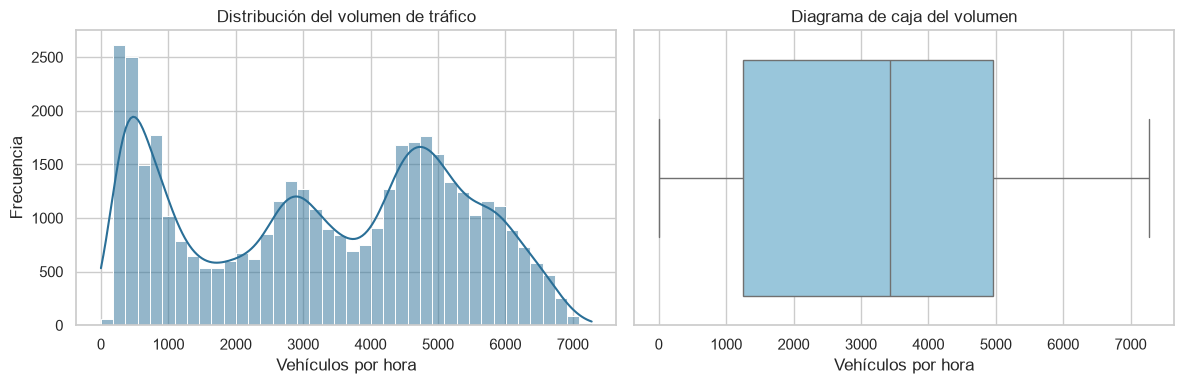

,count,mean,std,min,25%,50%,75%,max
traffic_volume,40575.0,3290.7,1984.8,0.0,1248.5,3427.0,4952.0,7280.0


In [8]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["traffic_volume"], bins=40, kde=True, ax=ejes[0], color="#2a6f97")
ejes[0].set(title="Distribución del volumen de tráfico", xlabel="Vehículos por hora", ylabel="Frecuencia")
sns.boxplot(x=df["traffic_volume"], ax=ejes[1], color="#8ecae6")
ejes[1].set(title="Diagrama de caja del volumen", xlabel="Vehículos por hora")
guardar("eda_distribucion_volumen")
plt.show()
df["traffic_volume"].describe().round(1).to_frame().T

*Interpretación:* revisa si la distribución es bimodal (horas valle frente a horas pico) y qué porcentaje de las horas tiene volumen muy bajo. Esto condiciona los umbrales de bajo/medio/alto.

### A.5 Patrones por hora, día y mes

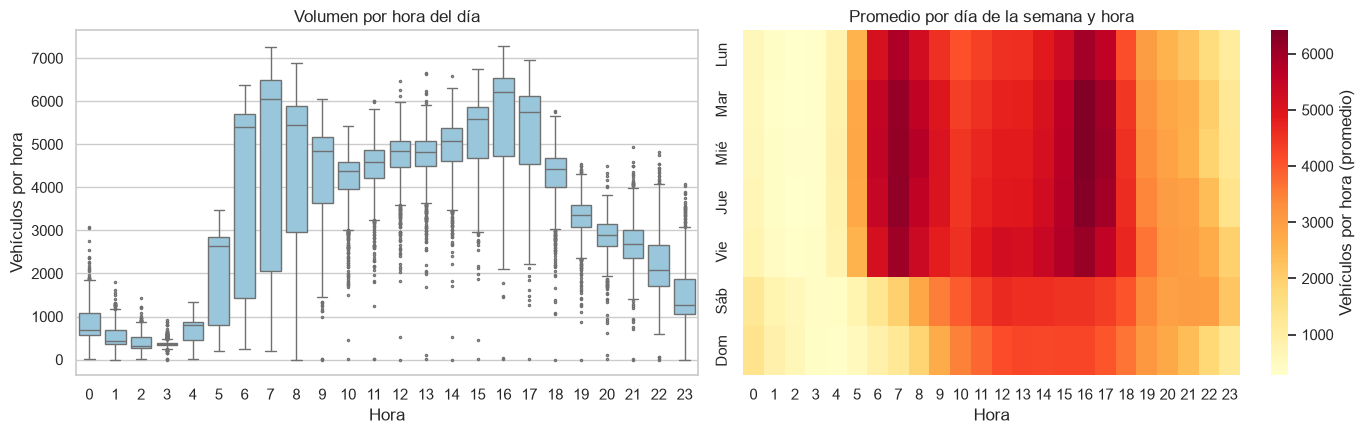

In [9]:
fig, ejes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.boxplot(data=df, x="hora", y="traffic_volume", ax=ejes[0], color="#8ecae6", fliersize=1.5)
ejes[0].set(title="Volumen por hora del día", xlabel="Hora", ylabel="Vehículos por hora")

pivote = df.pivot_table(index="dia_semana", columns="hora", values="traffic_volume", aggfunc="mean")
pivote.index = ["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"]
sns.heatmap(pivote, cmap="YlOrRd", ax=ejes[1], cbar_kws={"label": "Vehículos por hora (promedio)"})
ejes[1].set(title="Promedio por día de la semana y hora", xlabel="Hora", ylabel="")
guardar("eda_hora_dia")
plt.show()

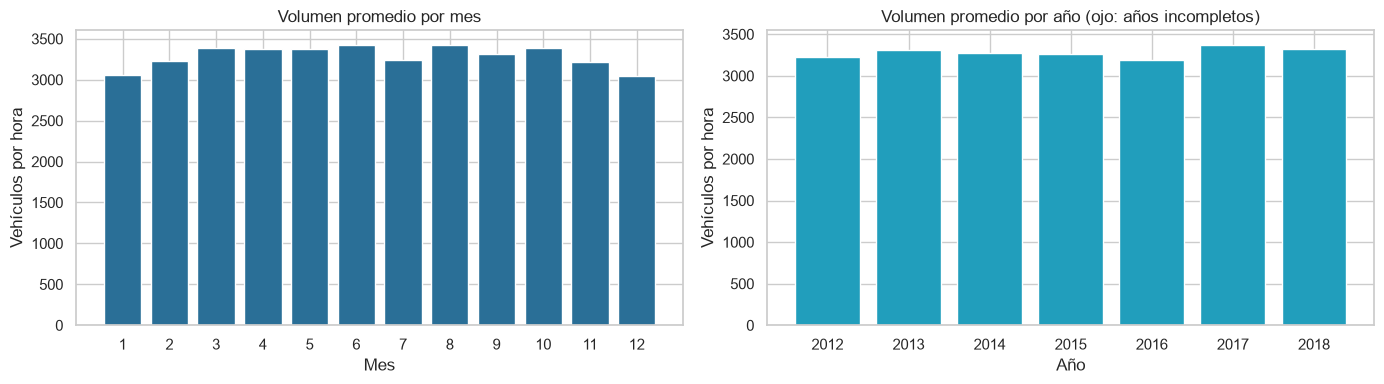

,mean,size
anio,,
2012,3226.701854,2103
2013,3309.552783,7294
2014,3270.143301,4501
2015,3258.042026,3593
2016,3193.695203,7838
2017,3376.589120,8713
2018,3323.901270,6533


In [10]:
fig, ejes = plt.subplots(1, 2, figsize=(14, 4))
mensual = df.groupby("mes")["traffic_volume"].mean()
ejes[0].bar(mensual.index, mensual.values, color="#2a6f97")
ejes[0].set(title="Volumen promedio por mes", xlabel="Mes", ylabel="Vehículos por hora", xticks=range(1, 13))

anual = df.groupby("anio")["traffic_volume"].agg(["mean", "size"])
ejes[1].bar(anual.index.astype(str), anual["mean"], color="#219ebc")
ejes[1].set(title="Volumen promedio por año (ojo: años incompletos)", xlabel="Año", ylabel="Vehículos por hora")
guardar("eda_mes_anio")
plt.show()
anual

*Interpretación:* identifica las horas pico de laborables, cómo cambian los fines de semana y si hay estacionalidad mensual.

### A.6 Efecto de festivos y clima

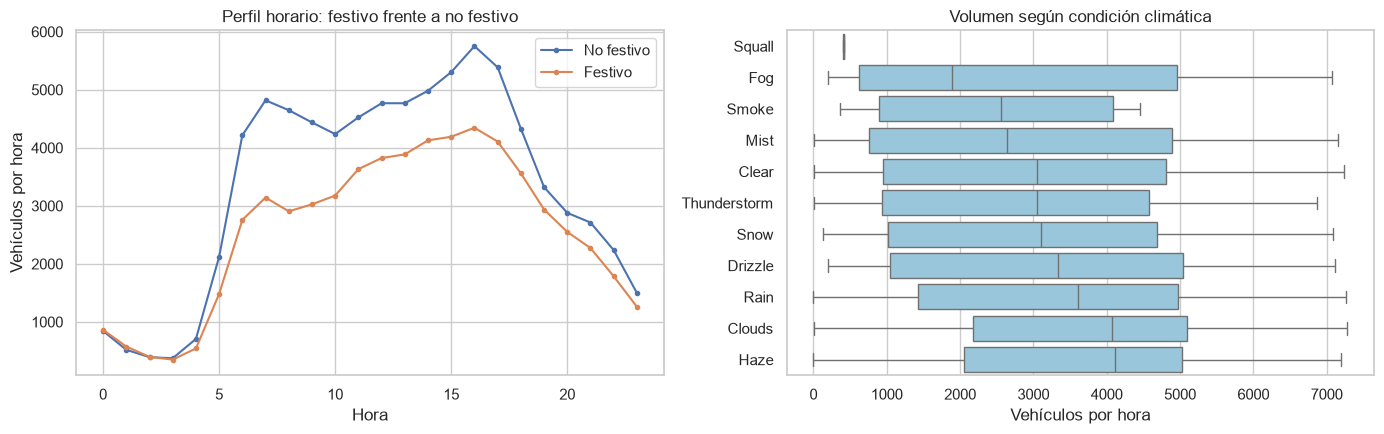

In [11]:
fig, ejes = plt.subplots(1, 2, figsize=(14, 4.5))
perfil = df.groupby(["festivo_dia", "hora"])["traffic_volume"].mean().unstack(0)
perfil.columns = ["No festivo", "Festivo"]
perfil.plot(ax=ejes[0], marker="o", ms=3)
ejes[0].set(title="Perfil horario: festivo frente a no festivo", xlabel="Hora", ylabel="Vehículos por hora")

orden = df.groupby("weather_main")["traffic_volume"].median().sort_values().index
sns.boxplot(data=df, y="weather_main", x="traffic_volume", order=orden, ax=ejes[1], color="#8ecae6", fliersize=1.5)
ejes[1].set(title="Volumen según condición climática", xlabel="Vehículos por hora", ylabel="")
guardar("eda_festivos_clima")
plt.show()

*Interpretación:* ¿los festivos se parecen a un fin de semana? ¿El clima cambia mucho el volumen una vez que se controla la hora? (la hora suele explicar mucho más que la lluvia).

### A.7 Correlaciones

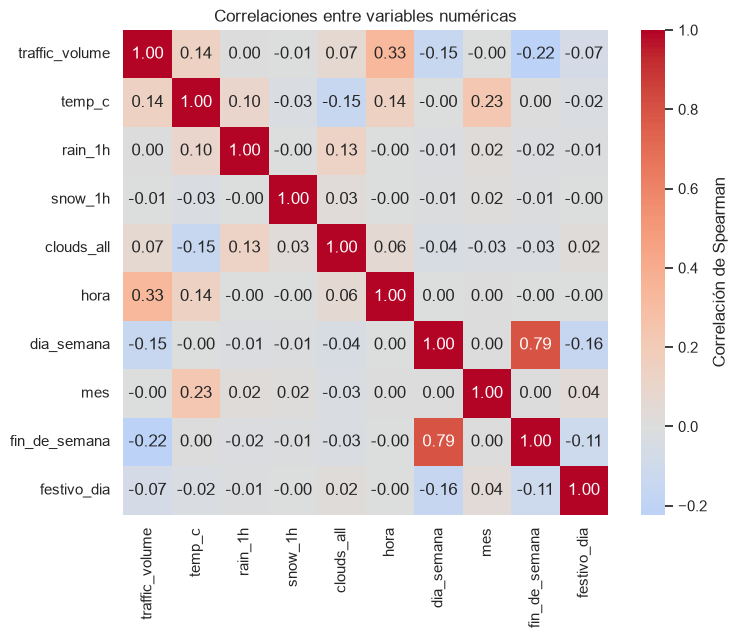

In [12]:
numericas = ["traffic_volume", "temp_c", "rain_1h", "snow_1h", "clouds_all",
             "hora", "dia_semana", "mes", "fin_de_semana", "festivo_dia"]
corr = df[numericas].astype(float).corr(method="spearman")
plt.figure(figsize=(8, 6.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True,
            cbar_kws={"label": "Correlación de Spearman"})
plt.title("Correlaciones entre variables numéricas")
guardar("eda_correlaciones")
plt.show()

*Interpretación:* la correlación lineal con `hora` puede ser baja aunque la hora sea decisiva (relación no lineal, con dos picos). Por eso se usan árboles y bosques en la semana 2.

### A.8 Valores atípicos

In [13]:
def atipicos_iqr(s):
    s = s.dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    rango = q3 - q1
    inf, sup = q1 - 1.5 * rango, q3 + 1.5 * rango
    return pd.Series({"q1": q1, "q3": q3, "lim_inf": inf, "lim_sup": sup,
                      "n_atipicos": int(((s < inf) | (s > sup)).sum()),
                      "maximo": s.max(), "minimo": s.min()})

tabla_atip = pd.DataFrame({c: atipicos_iqr(df[c]) for c in ["traffic_volume", "temp_c", "rain_1h", "snow_1h", "clouds_all"]}).T
tabla_atip.round(2)

,q1,q3,lim_inf,lim_sup,n_atipicos,maximo,minimo
traffic_volume,1248.5,4952.00,-4306.75,10507.25,0.0,7280.00,0.00
temp_c,-1.3,19.13,-31.94,49.77,0.0,36.92,-29.76
rain_1h,0.0,0.00,0.00,0.00,2053.0,55.63,0.00
snow_1h,0.0,0.00,0.00,0.00,31.0,0.51,0.00
clouds_all,1.0,90.00,-132.50,223.50,0.0,100.00,0.00


In [14]:
print("Temperaturas inválidas (≤ 0 K) detectadas:", resumen["temp_invalidas"])
print("Lluvias atípicas (> 500 mm/h) detectadas:", resumen["lluvia_atipica"])
print("\n% de horas con lluvia > 0:", round((df["rain_1h"] > 0).mean() * 100, 2))
print("% de horas con nieve > 0:", round((df["snow_1h"] > 0).mean() * 100, 2))

Temperaturas inválidas (≤ 0 K) detectadas: 10
Lluvias atípicas (> 500 mm/h) detectadas: 1

% de horas con lluvia > 0: 5.06
% de horas con nieve > 0: 0.08


*Interpretación:* `rain_1h` y `snow_1h` están casi siempre en cero, así que los IQR marcan como «atípico» casi cualquier lluvia. Se decide no eliminar esos valores (son lluvia real) y solo anular los imposibles (temperatura ≤ 0 K y lluvia > 500 mm/h).

### A.9 Variable objetivo: nivel de tráfico (bajo, medio, alto)

Cortes por terciles: bajo ≤ 2274 < medio ≤ 4598 < alto


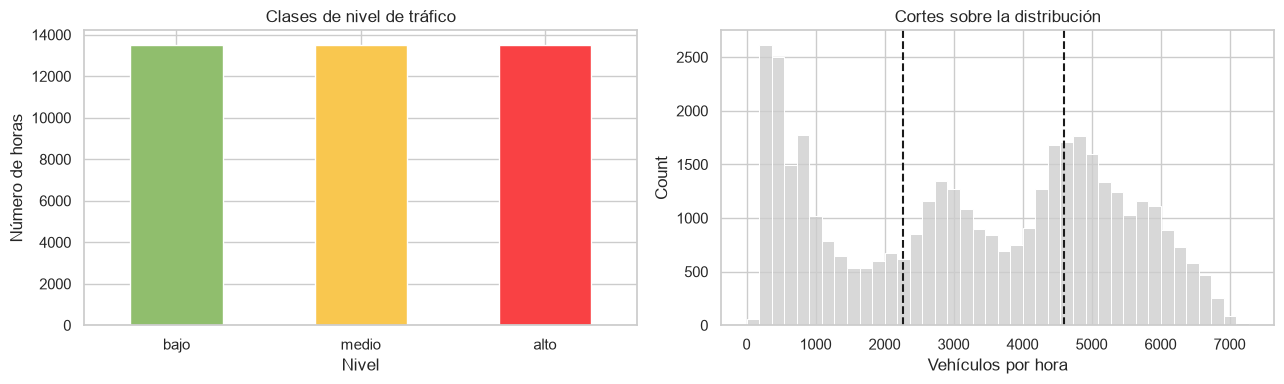

hora,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
nivel_trafico,,,,,,,,,,,,,,,,,,,,,,,,
bajo,1.0,1.0,1.0,1.0,1.0,0.33,0.30,0.28,0.17,0.03,0.01,0.01,0.00,0.00,0.00,0.00,0.00,0.01,0.01,0.02,0.07,0.2,0.59,0.9
medio,0.0,0.0,0.0,0.0,0.0,0.67,0.04,0.06,0.19,0.36,0.74,0.50,0.31,0.31,0.24,0.23,0.22,0.27,0.65,0.98,0.93,0.8,0.41,0.1
alto,0.0,0.0,0.0,0.0,0.0,0.00,0.66,0.66,0.65,0.60,0.25,0.50,0.68,0.68,0.76,0.77,0.77,0.73,0.34,0.00,0.00,0.0,0.00,0.0


In [15]:
cortes = datos.cortes_nivel(df["traffic_volume"])
df["nivel_trafico"] = datos.asignar_nivel(df["traffic_volume"], cortes)
print(f"Cortes por terciles: bajo ≤ {cortes[0]:.0f} < medio ≤ {cortes[1]:.0f} < alto")

fig, ejes = plt.subplots(1, 2, figsize=(13, 4))
df["nivel_trafico"].value_counts().reindex(config.NIVELES).plot.bar(ax=ejes[0], color=["#90be6d", "#f9c74f", "#f94144"], rot=0)
ejes[0].set(title="Clases de nivel de tráfico", xlabel="Nivel", ylabel="Número de horas")

sns.histplot(df["traffic_volume"], bins=40, ax=ejes[1], color="#cccccc")
for c in cortes:
    ejes[1].axvline(c, color="k", ls="--")
ejes[1].set(title="Cortes sobre la distribución", xlabel="Vehículos por hora")
guardar("eda_nivel_trafico")
plt.show()

pd.crosstab(df["hora"], df["nivel_trafico"], normalize="index").round(2).T

> **Nota para la semana 2:** aquí los terciles se calculan con todos los datos solo para explorar. En el entrenamiento supervisado hay que calcular los cortes **únicamente con el conjunto de entrenamiento** y aplicarlos a prueba, para evitar fuga de información.

### A.10 Perfiles horarios diarios (base del módulo no supervisado)

Días totales en los datos: 1,860
Días con las 24 horas completas: 1,214
Días utilizables tolerando hasta 3 horas faltantes (interpoladas): 1,508


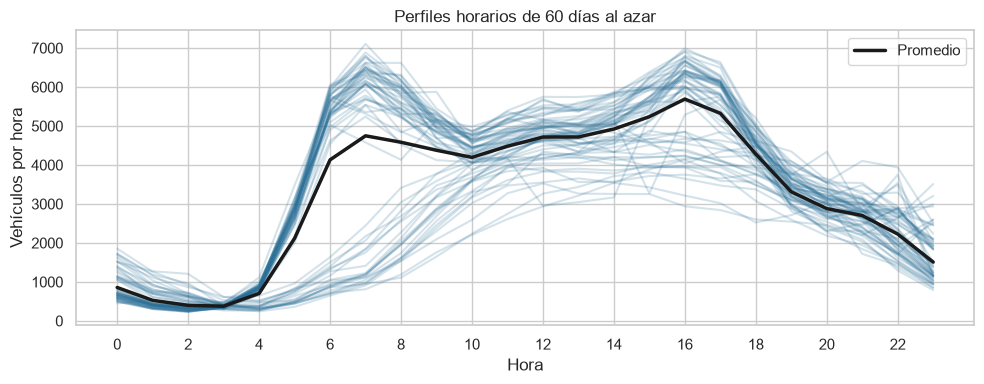

In [16]:
estricto = datos.perfil_horario_diario(df, max_faltantes=0)
tolerante = datos.perfil_horario_diario(df, max_faltantes=3)
print(f"Días totales en los datos: {df['fecha'].nunique():,}")
print(f"Días con las 24 horas completas: {len(estricto):,}")
print(f"Días utilizables tolerando hasta 3 horas faltantes (interpoladas): {len(tolerante):,}")

fig, ax = plt.subplots(figsize=(10, 4))
for _, fila in estricto.sample(min(60, len(estricto)), random_state=config.SEMILLA).iterrows():
    ax.plot(range(24), fila.values, alpha=0.2, color="#2a6f97")
ax.plot(range(24), estricto.mean().values, color="k", lw=2.5, label="Promedio")
ax.set(title="Perfiles horarios de 60 días al azar", xlabel="Hora", ylabel="Vehículos por hora", xticks=range(0, 24, 2))
ax.legend()
guardar("eda_perfiles_diarios")
plt.show()

*Interpretación:* se aprecian al menos dos formas de día (con dos picos o con un solo pico suave). Esa estructura es lo que K-Means y DBSCAN intentarán descubrir. Decide en el equipo si se trabaja con los días estrictos o con los tolerantes.

### A.11 Guardar datos limpios

In [17]:
config.DATA_PROCESSED.mkdir(parents=True, exist_ok=True)
df.to_csv(config.CSV_TRAFICO_LIMPIO, index=False)
print("Guardado:", config.CSV_TRAFICO_LIMPIO, df.shape)

Guardado: C:\Users\pajar\OneDrive\Documentos\Uni\IAVOID\Proyecto\proyecto_ia_semana1\proyecto_ia\data\processed\traffic_clean.csv (40575, 19)


## Parte B · Dataset de imágenes: GTSRB

In [18]:
entren = datos.carpeta_entrenamiento_gtsrb()
if entren is None:
    print("⚠ No se encontró GTSRB. Ejecuta: python src/descargar_datos.py --imagenes")
else:
    conteo = datos.conteo_por_clase(entren)
    print("Carpeta:", entren)
    print(f"Clases: {len(conteo)} | imágenes de entrenamiento: {conteo.sum():,}")

Carpeta: C:\Users\pajar\OneDrive\Documentos\Uni\IAVOID\Proyecto\proyecto_ia_semana1\proyecto_ia\data\raw\gtsrb\gtsrb\GTSRB\Training
Clases: 43 | imágenes de entrenamiento: 26,640


### B.1 Conteo por clase y desbalance

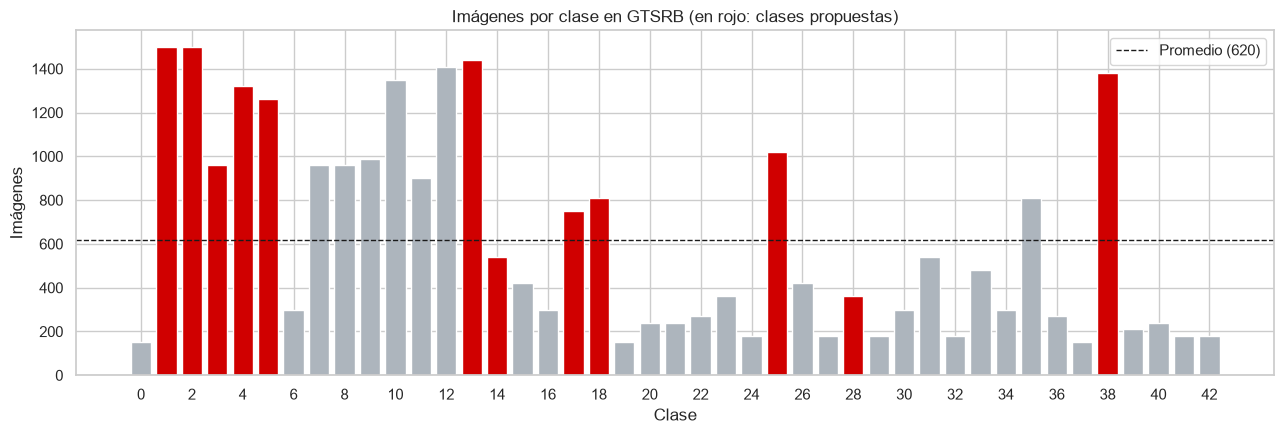

Razón máx/mín (desbalance): 10.0x
Subconjunto propuesto: 12 clases, 12,840 imágenes, razón máx/mín 4.2x


In [19]:
if entren is not None:
    fig, ax = plt.subplots(figsize=(13, 4.5))
    colores = ["#d00000" if c in config.SUBSET_CLASES else "#adb5bd" for c in conteo.index]
    ax.bar(conteo.index, conteo.values, color=colores)
    ax.axhline(conteo.mean(), color="k", ls="--", lw=1, label=f"Promedio ({conteo.mean():.0f})")
    ax.set(title="Imágenes por clase en GTSRB (en rojo: clases propuestas)", xlabel="Clase", ylabel="Imágenes", xticks=range(0, 43, 2))
    ax.legend()
    guardar("eda_gtsrb_conteo")
    plt.show()

    print(f"Razón máx/mín (desbalance): {conteo.max() / conteo.min():.1f}x")
    sub = conteo.loc[config.SUBSET_CLASES].to_frame()
    sub["nombre"] = [config.NOMBRES_CLASES[c] for c in sub.index]
    print(f"Subconjunto propuesto: {len(sub)} clases, {sub['imagenes'].sum():,} imágenes, razón máx/mín {sub['imagenes'].max() / sub['imagenes'].min():.1f}x")
    sub

*Interpretación:* el conjunto está desbalanceado. Para la CNN se puede compensar con aumento de datos, pesos por clase o muestreo equilibrado. Además, GTSRB trae cada señal física en secuencias de ~30 fotos casi iguales: **al separar entrenamiento y validación hay que separar por secuencia/pista**, no por imagen suelta, o la validación saldrá artificialmente alta.

### B.2 Ejemplos por clase

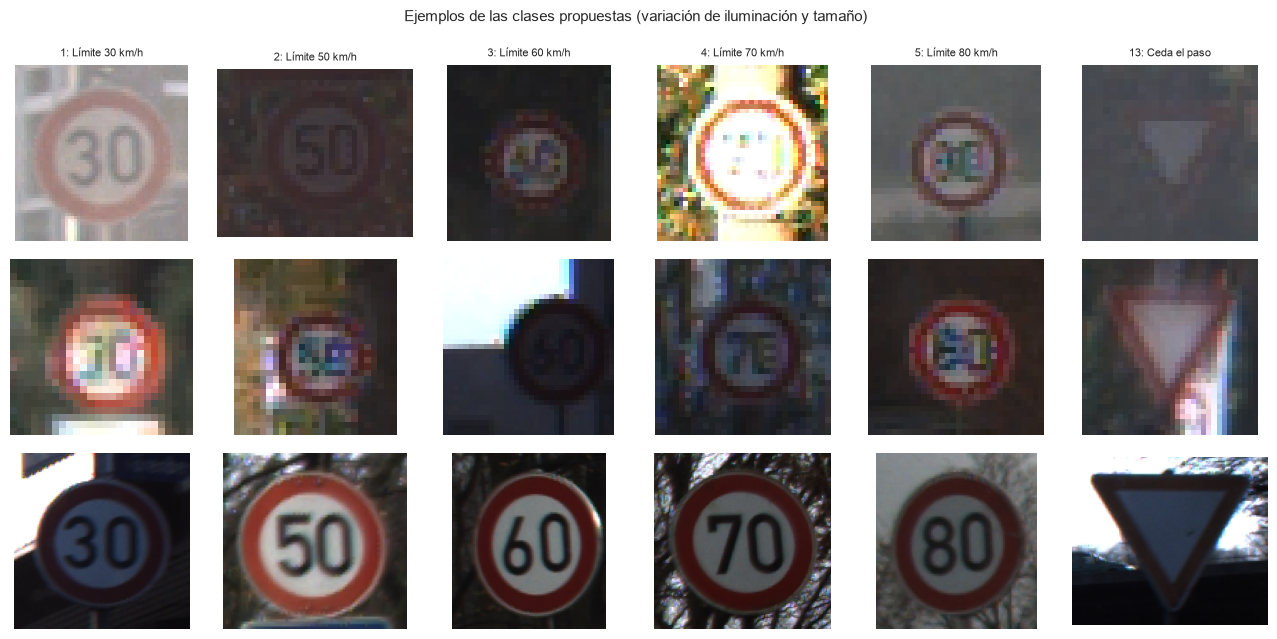

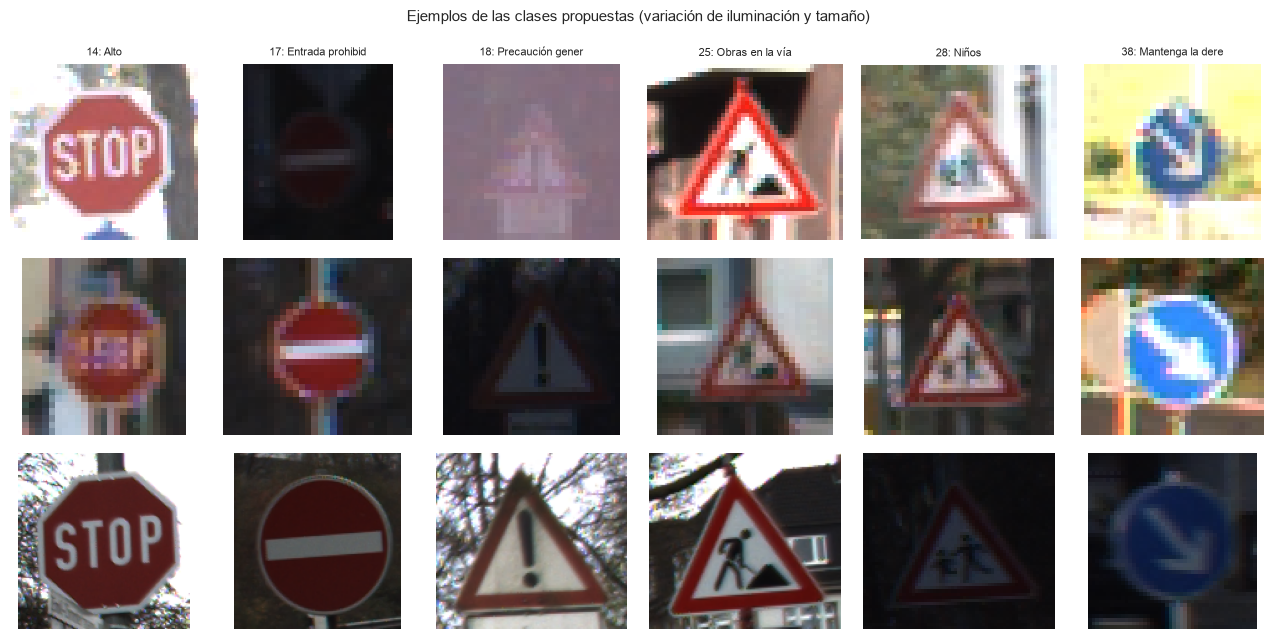

In [20]:
if entren is not None:
    for inicio in (0, 6):
        fig, ejes = plt.subplots(3, 6, figsize=(13, 6.5))
        clases = config.SUBSET_CLASES[inicio:inicio + 6]
        for col, c in enumerate(clases):
            rutas = datos.imagenes_de_clase(entren, c)
            elegidas = [rutas[0], rutas[len(rutas) // 2], rutas[-1]]
            for fila, ruta in enumerate(elegidas):
                ax = ejes[fila, col]
                ax.imshow(Image.open(ruta))
                ax.axis("off")
                if fila == 0:
                    ax.set_title(f"{c}: {config.NOMBRES_CLASES[c][:16]}", fontsize=8)
        fig.suptitle("Ejemplos de las clases propuestas (variación de iluminación y tamaño)", fontsize=11)
        guardar(f"eda_gtsrb_ejemplos_{inicio // 6 + 1}")
        plt.show()

### B.3 Tamaños de imagen y brillo

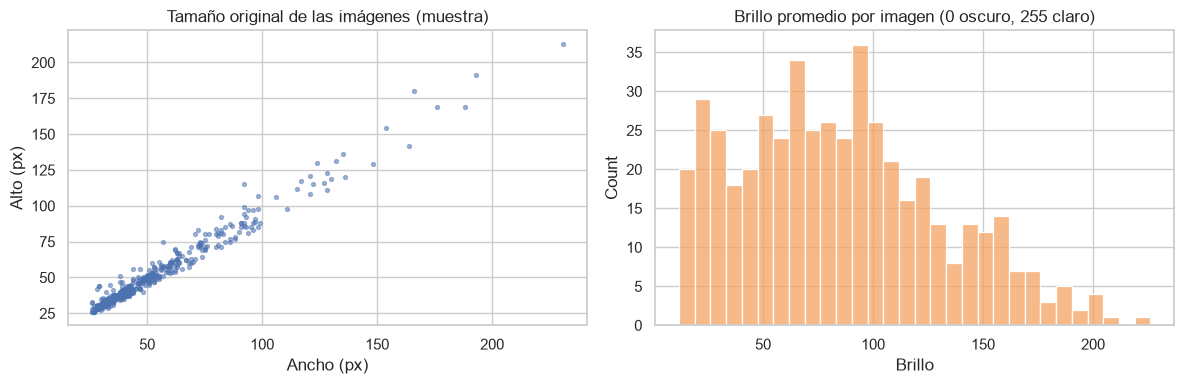

        count  mean   std   min   25%   50%    75%    max
ancho   480.0  52.2  27.6  26.0  35.0  42.0   60.0  231.0
alto    480.0  51.5  26.0  26.0  35.0  43.0   58.0  213.0
brillo  480.0  85.1  45.6  11.8  49.4  81.0  113.9  226.1


In [21]:
if entren is not None:
    rng = np.random.default_rng(config.SEMILLA)
    muestra = []
    for c in config.SUBSET_CLASES:
        rutas = datos.imagenes_de_clase(entren, c)
        for i in rng.choice(len(rutas), size=min(40, len(rutas)), replace=False):
            with Image.open(rutas[i]) as im:
                ancho, alto = im.size
                brillo = np.asarray(im.convert("L")).mean()
            muestra.append({"clase": c, "ancho": ancho, "alto": alto, "brillo": brillo})
    m = pd.DataFrame(muestra)

    fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
    ejes[0].scatter(m["ancho"], m["alto"], s=8, alpha=0.5)
    ejes[0].set(title="Tamaño original de las imágenes (muestra)", xlabel="Ancho (px)", ylabel="Alto (px)")
    sns.histplot(m["brillo"], bins=30, ax=ejes[1], color="#f4a261")
    ejes[1].set(title="Brillo promedio por imagen (0 oscuro, 255 claro)", xlabel="Brillo")
    guardar("eda_gtsrb_tamano_brillo")
    plt.show()
    print(m[["ancho", "alto", "brillo"]].describe().round(1).T)

*Interpretación:* los tamaños varían mucho, por lo que habrá que redimensionar todo a 32 × 32 o 48 × 48. Si hay muchas imágenes oscuras, conviene aumento de brillo/contraste.

## Parte C · Variable objetivo y métricas de cada módulo

| Módulo | Variable objetivo / tarea | Métricas principales | Notas |
|---|---|---|---|
| Supervisado | `nivel_trafico` (bajo, medio, alto) creado con terciles de `traffic_volume`, calculados solo con entrenamiento | Exactitud, **F1 macro**, matriz de confusión; validación cruzada de 5 particiones | Entradas: hora, día de la semana, temperatura, lluvia y festivo. Se interpretará en qué horas se confunden los niveles. |
| No supervisado | Perfil horario de 24 valores por día (sin etiqueta) | Método del codo, **coeficiente de silueta**, proporción de ruido en DBSCAN | Se escala con `StandardScaler`; PCA solo para visualizar. |
| CNN | Clase de señal (12 clases propuestas de GTSRB) | Exactitud, matriz de confusión, señales más confundidas | Separar por secuencia; aumento de datos; imágenes de 32 × 32 o 48 × 48. |
| Refuerzo | Política de semáforo de dos fases | **Espera promedio por auto** frente a semáforo de tiempo fijo; recompensa por episodio | Entorno Gymnasium propio; Q-learning tabular con epsilon decreciente. |

## Conclusiones del EDA
*Completa con 4 a 6 hallazgos concretos que cambien decisiones del proyecto. Ejemplos de la forma esperada (sustituye por lo que veas en tus datos):*

1. Hallazgo sobre la calidad de los datos → decisión tomada.
2. Hallazgo sobre patrones horarios → qué variables serán más importantes.
3. Hallazgo sobre festivos y clima → cómo se tratarán.
4. Hallazgo sobre el desbalance de imágenes → cómo se compensará.
5. Riesgos y limitaciones detectados.